In [1]:
import sys
print(sys.version)
%pip install pandas numpy scikit-learn matplotlib seaborn imbalanced-learn xgboost


3.13.10 (tags/v3.13.10:4fd8843, Dec  2 2025, 15:08:18) [MSC v.1944 64 bit (AMD64)]
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: C:\Program Files\Python313\python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd

train = pd.read_csv("KDDTrain+.txt", header=None)
test = pd.read_csv("KDDTest+.txt", header=None)

print(train.shape, test.shape)
train.head()

(125973, 43) (22544, 43)


,0,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [3]:
columns = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root",
    "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count", "srv_count", "serror_rate",
    "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "label", "difficulty"
]

train.columns = columns
test.columns = columns

print(train["label"].value_counts().head(10))
train.head()

label
normal         67343
neptune        41214
satan           3633
ipsweep         3599
portsweep       2931
smurf           2646
nmap            1493
back             956
teardrop         892
warezclient      890
Name: count, dtype: int64


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [4]:
train["target"] = (train["label"] != "normal").astype(int)
test["target"] = (test["label"] != "normal").astype(int)

print(train["target"].value_counts())
print()
print(train["target"].value_counts(normalize=True).round(3))
print()
print(test["target"].value_counts(normalize=True).round(3))

target
0    67343
1    58630
Name: count, dtype: int64

target
0    0.535
1    0.465
Name: proportion, dtype: float64

target
1    0.569
0    0.431
Name: proportion, dtype: float64


In [5]:
print("Missing values (train, test):", train.isnull().sum().sum(), test.isnull().sum().sum())
print("Duplicate rows (train, test):", train.duplicated().sum(), test.duplicated().sum())
print()
print("Column types:")
print(train.dtypes.value_counts())
print()
print("Categories in each text column:")
print(train[["protocol_type", "service", "flag"]].nunique())
print()
nunique = train.nunique()
print("Columns with only one value:", list(nunique[nunique == 1].index))

Missing values (train, test): 0 0
Duplicate rows (train, test): 0 0

Column types:
int64      25
float64    15
str         4
Name: count, dtype: int64

Categories in each text column:
protocol_type     3
service          70
flag             11
dtype: int64

Columns with only one value: ['num_outbound_cmds']


In [6]:
# drop columns we don't need
train = train.drop(columns=["num_outbound_cmds", "difficulty"])
test = test.drop(columns=["num_outbound_cmds", "difficulty"])

# check for categories in the test set that never appear in training
for col in ["protocol_type", "service", "flag"]:
    unseen = set(test[col]) - set(train[col])
    print(col, "-> in test but not in train:", unseen)

print(train.shape, test.shape)

protocol_type -> in test but not in train: set()
service -> in test but not in train: set()
flag -> in test but not in train: set()
(125973, 42) (22544, 42)


In [7]:
# save cleaned versions (a deliverable for your repo)
train.to_csv("train_clean.csv", index=False)
test.to_csv("test_clean.csv", index=False)

# quick look at a few numeric columns
train[["duration", "src_bytes", "dst_bytes", "count", "serror_rate"]].describe().round(2)

,duration,src_bytes,dst_bytes,count,serror_rate
count,125973.00,1.259730e+05,1.259730e+05,125973.00,125973.00
mean,287.14,4.556674e+04,1.977911e+04,84.11,0.28
std,2604.52,5.870331e+06,4.021269e+06,114.51,0.45
min,0.00,0.000000e+00,0.000000e+00,0.00,0.00
25%,0.00,0.000000e+00,0.000000e+00,2.00,0.00
50%,0.00,4.400000e+01,0.000000e+00,14.00,0.00
75%,0.00,2.760000e+02,5.160000e+02,143.00,1.00
max,42908.00,1.379964e+09,1.309937e+09,511.00,1.00


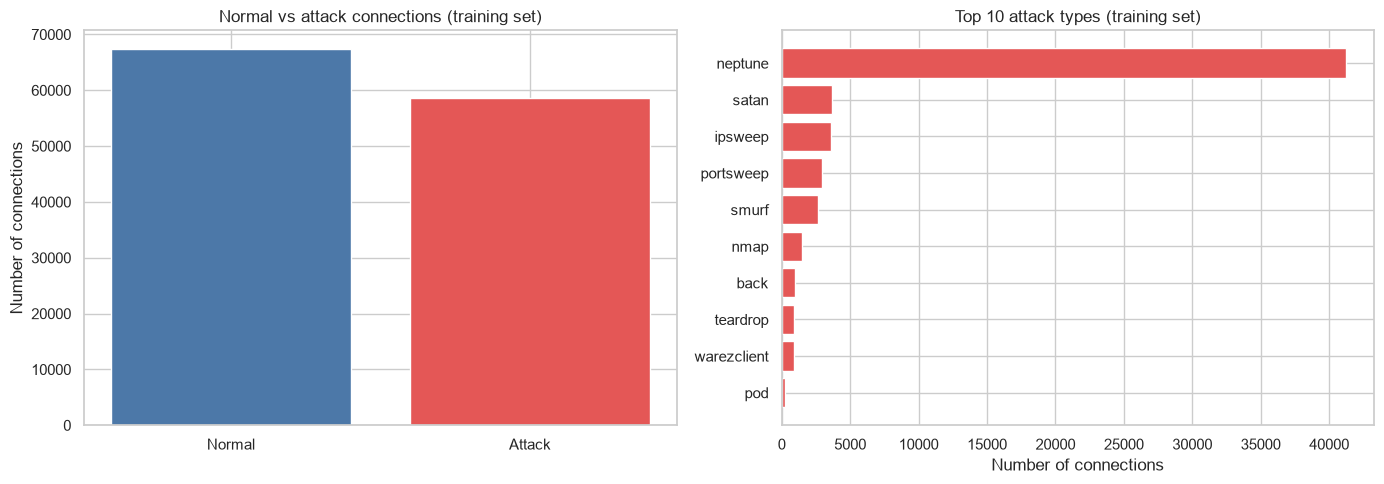

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# chart 1: normal vs attack
counts = train["target"].map({0: "Normal", 1: "Attack"}).value_counts()
axes[0].bar(counts.index, counts.values, color=["#4C78A8", "#E45756"])
axes[0].set_title("Normal vs attack connections (training set)")
axes[0].set_ylabel("Number of connections")

# chart 2: most common attack types
attack_counts = train[train["label"] != "normal"]["label"].value_counts().head(10)
axes[1].barh(attack_counts.index[::-1], attack_counts.values[::-1], color="#E45756")
axes[1].set_title("Top 10 attack types (training set)")
axes[1].set_xlabel("Number of connections")

plt.tight_layout()
plt.show()

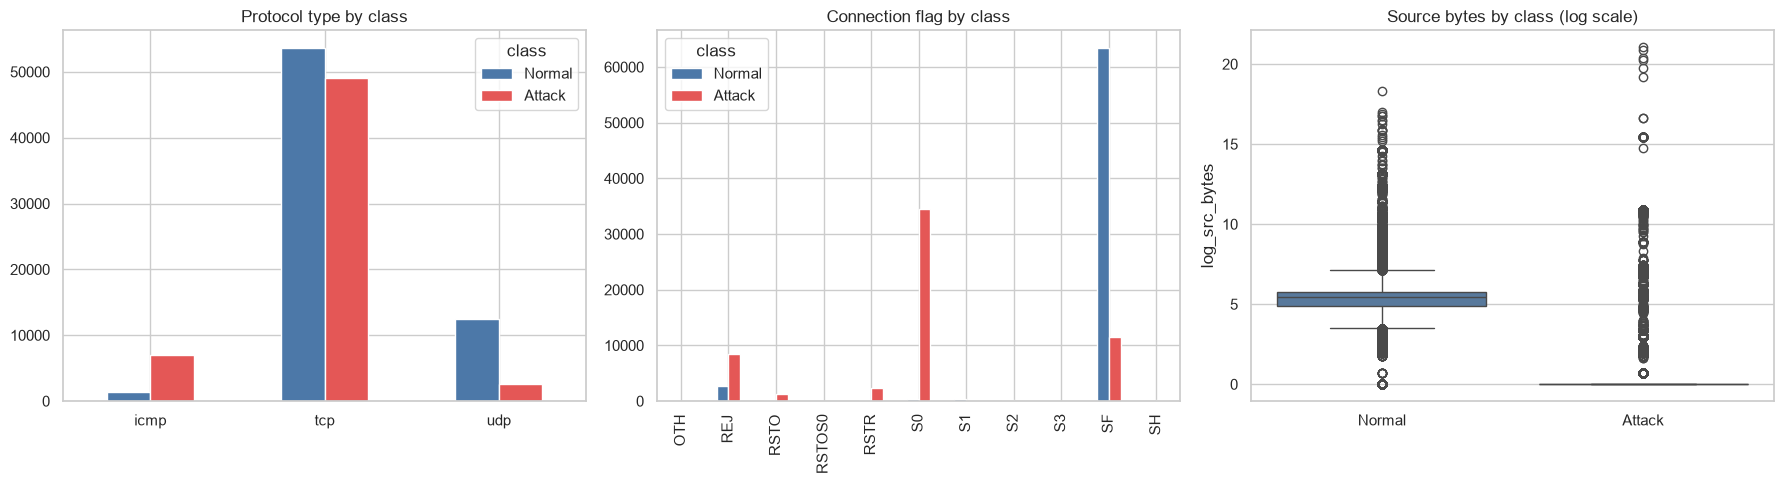

In [9]:
import numpy as np

plot_df = train.copy()
plot_df["class"] = plot_df["target"].map({0: "Normal", 1: "Attack"})
plot_df["log_src_bytes"] = np.log1p(plot_df["src_bytes"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# chart 1: protocol type by class
ct1 = pd.crosstab(plot_df["protocol_type"], plot_df["class"])[["Normal", "Attack"]]
ct1.plot(kind="bar", ax=axes[0], color=["#4C78A8", "#E45756"])
axes[0].set_title("Protocol type by class")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)

# chart 2: connection flag by class
ct2 = pd.crosstab(plot_df["flag"], plot_df["class"])[["Normal", "Attack"]]
ct2.plot(kind="bar", ax=axes[1], color=["#4C78A8", "#E45756"])
axes[1].set_title("Connection flag by class")
axes[1].set_xlabel("")

# chart 3: bytes sent from the source (log scale)
sns.boxplot(data=plot_df, x="class", y="log_src_bytes", hue="class",
            order=["Normal", "Attack"], legend=False, ax=axes[2],
            palette={"Normal": "#4C78A8", "Attack": "#E45756"})
axes[2].set_title("Source bytes by class (log scale)")
axes[2].set_xlabel("")

plt.tight_layout()
plt.show()

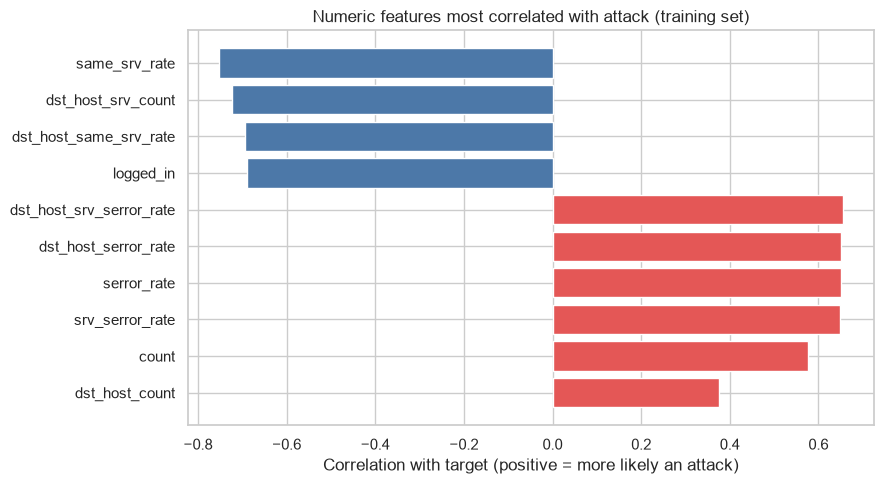

same_srv_rate              -0.75
dst_host_srv_count         -0.72
dst_host_same_srv_rate     -0.69
logged_in                  -0.69
dst_host_srv_serror_rate    0.65
dst_host_serror_rate        0.65
serror_rate                 0.65
srv_serror_rate             0.65
count                       0.58
dst_host_count              0.38
dtype: float64


In [10]:
num_cols = train.select_dtypes(include="number").drop(columns="target")
corr = num_cols.corrwith(train["target"]).sort_values(key=abs, ascending=False)
top = corr.head(10)

plt.figure(figsize=(9, 5))
plt.barh(top.index[::-1], top.values[::-1],
         color=["#E45756" if v > 0 else "#4C78A8" for v in top.values[::-1]])
plt.title("Numeric features most correlated with attack (training set)")
plt.xlabel("Correlation with target (positive = more likely an attack)")
plt.tight_layout()
plt.show()

print(top.round(2))

In [11]:
feature_cols = [c for c in train.columns if c not in ["label", "target"]]
cat_cols = ["protocol_type", "service", "flag"]

# one-hot encode the three text columns
X_train = pd.get_dummies(train[feature_cols], columns=cat_cols, dtype=int)
X_test = pd.get_dummies(test[feature_cols], columns=cat_cols, dtype=int)

# make sure both sets have exactly the same columns in the same order
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

y_train = train["target"]
y_test = test["target"]

print(X_train.shape, X_test.shape)
print("Columns only in train:", X_train.columns.difference(X_test.columns).tolist())

(125973, 121) (22544, 121)
Columns only in train: []


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# reload the cleaned data saved on Day 2
train = pd.read_csv("train_clean.csv")
test = pd.read_csv("test_clean.csv")
print(train.shape, test.shape)

# set up inputs and answers
feature_cols = [c for c in train.columns if c not in ["label", "target"]]
cat_cols = ["protocol_type", "service", "flag"]

# one-hot encode the three text columns
X_train = pd.get_dummies(train[feature_cols], columns=cat_cols, dtype=int)
X_test = pd.get_dummies(test[feature_cols], columns=cat_cols, dtype=int)

# make sure both sets have exactly the same columns in the same order
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

y_train = train["target"]
y_test = test["target"]

print(X_train.shape, X_test.shape)
print("Columns only in train:", X_train.columns.difference(X_test.columns).tolist())

(125973, 42) (22544, 42)
(125973, 121) (22544, 121)
Columns only in train: []


In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# separate copies for logistic regression
X_train_lr = X_train.copy()
X_test_lr = X_test.copy()

# log transform the heavily skewed columns
for c in ["duration", "src_bytes", "dst_bytes"]:
    X_train_lr[c] = np.log1p(X_train_lr[c])
    X_test_lr[c] = np.log1p(X_test_lr[c])

# scale the numeric columns (fit on training data only)
num_cols = [c for c in feature_cols if c not in cat_cols]
scaler = StandardScaler()
X_train_lr[num_cols] = scaler.fit_transform(X_train_lr[num_cols])
X_test_lr[num_cols] = scaler.transform(X_test_lr[num_cols])

# train the baseline model
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_lr, y_train)

pred = lr.predict(X_test_lr)
print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print()
print(classification_report(y_test, pred, target_names=["Normal", "Attack"]))

Accuracy: 0.752

              precision    recall  f1-score   support

      Normal       0.65      0.92      0.76      9711
      Attack       0.91      0.62      0.74     12833

    accuracy                           0.75     22544
   macro avg       0.78      0.77      0.75     22544
weighted avg       0.80      0.75      0.75     22544



In [14]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

def summarise(name, y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "False alarm rate": fp / (fp + tn),
    }

results = [summarise("Logistic regression", y_test, pred)]

rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
results.append(summarise("Random forest", y_test, rf.predict(X_test)))

xgb = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                    n_jobs=-1, random_state=42)
xgb.fit(X_train, y_train)
results.append(summarise("XGBoost", y_test, xgb.predict(X_test)))

results_df = pd.DataFrame(results).round(3)
results_df

,Model,Accuracy,Precision,Recall,F1,False alarm rate
0,Logistic regression,0.752,0.915,0.621,0.740,0.076
1,Random forest,0.776,0.969,0.627,0.762,0.027
2,XGBoost,0.793,0.968,0.659,0.784,0.028


In [15]:
xgb_pred = xgb.predict(X_test)

check = pd.DataFrame({"label": test["label"], "caught": xgb_pred})
attacks = check[check["label"] != "normal"]

by_type = attacks.groupby("label")["caught"].agg(["mean", "count"])
by_type.columns = ["detection_rate", "test_rows"]
by_type["seen_in_training"] = by_type.index.isin(train["label"].unique())
by_type = by_type.sort_values("test_rows", ascending=False).round(3)

by_type.head(15)

,detection_rate,test_rows,seen_in_training
label,,,
neptune,1.000,4657,True
guess_passwd,0.000,1231,True
mscan,0.297,996,False
warezmaster,0.184,944,True
apache2,0.817,737,False
satan,1.000,735,True
processtable,0.289,685,False
smurf,1.000,665,True
back,1.000,359,True


In [16]:
attacks = attacks.copy()
attacks["seen"] = attacks["label"].isin(train["label"].unique())
print(attacks.groupby("seen")["caught"].agg(["mean", "count"]).round(3))
print()

train_counts = train["label"].value_counts()
for t in ["neptune", "satan", "guess_passwd", "warezmaster"]:
    print(t, "-> rows in training:", train_counts.get(t, 0))

        mean  count
seen               
False  0.381   3750
True   0.773   9083

neptune -> rows in training: 41214
satan -> rows in training: 3633
guess_passwd -> rows in training: 53
warezmaster -> rows in training: 20


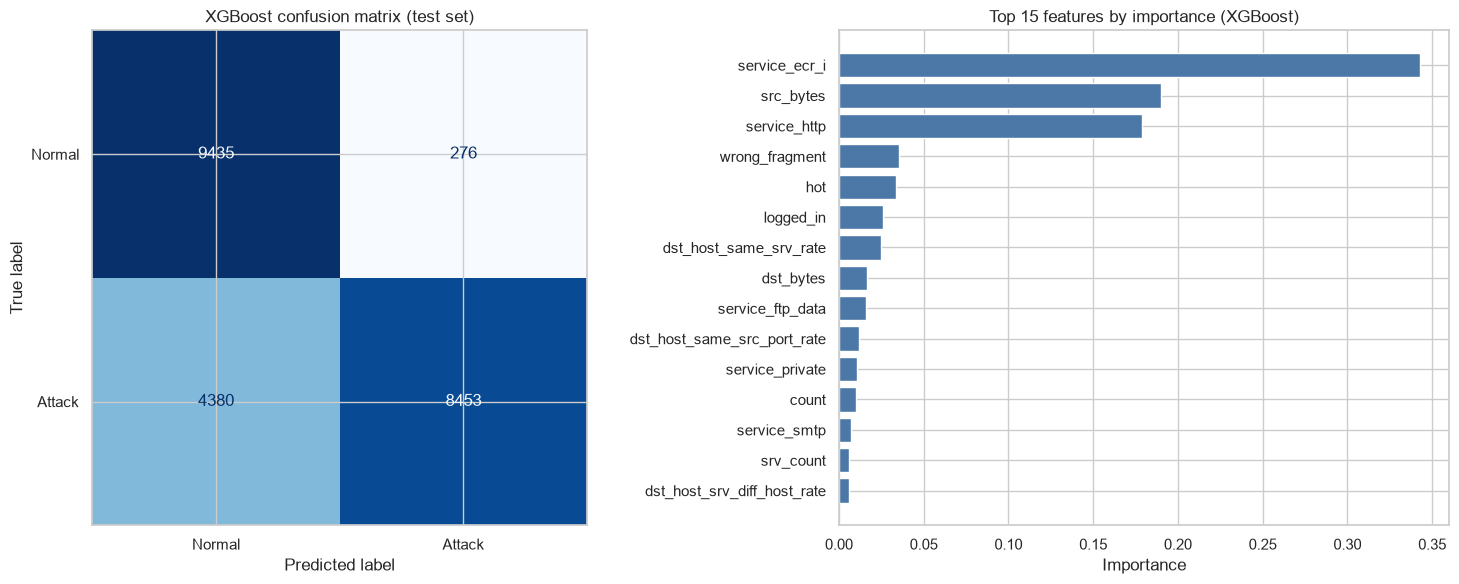

service_ecr_i                  0.343
src_bytes                      0.190
service_http                   0.179
wrong_fragment                 0.035
hot                            0.034
logged_in                      0.026
dst_host_same_srv_rate         0.025
dst_bytes                      0.017
service_ftp_data               0.016
dst_host_same_src_port_rate    0.012
service_private                0.010
count                          0.010
service_smtp                   0.007
srv_count                      0.006
dst_host_srv_diff_host_rate    0.006
dtype: float32


In [17]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test, xgb.predict(X_test),
    display_labels=["Normal", "Attack"], cmap="Blues",
    ax=axes[0], colorbar=False)
axes[0].set_title("XGBoost confusion matrix (test set)")

imp = pd.Series(xgb.feature_importances_, index=X_train.columns)
imp = imp.sort_values(ascending=False).head(15)
axes[1].barh(imp.index[::-1], imp.values[::-1], color="#4C78A8")
axes[1].set_title("Top 15 features by importance (XGBoost)")
axes[1].set_xlabel("Importance")

plt.tight_layout()
plt.show()
print(imp.round(3))

In [18]:
# predictions for every test row
export = test.copy()
export["xgb_pred"] = xgb.predict(X_test)
export["xgb_proba"] = xgb.predict_proba(X_test)[:, 1]
export["correct"] = (export["xgb_pred"] == export["target"]).astype(int)
export["seen_in_training"] = export["label"].isin(train["label"].unique())
export.to_csv("test_predictions.csv", index=False)

# summary tables
results_df.to_csv("model_results.csv", index=False)
by_type.reset_index().to_csv("detection_by_attack_type.csv", index=False)
imp.rename("importance").rename_axis("feature").reset_index().to_csv("feature_importance.csv", index=False)

print("Saved:", export.shape)

Saved: (22544, 46)


In [19]:
%%writefile app.py
import pandas as pd
import streamlit as st

st.set_page_config(page_title="NIDS Dashboard", layout="wide")


@st.cache_data
def load():
    return (
        pd.read_csv("model_results.csv"),
        pd.read_csv("detection_by_attack_type.csv"),
        pd.read_csv("feature_importance.csv"),
        pd.read_csv("test_predictions.csv"),
    )


results, by_type, imp, preds = load()

st.title("Network intrusion detection on NSL-KDD")
st.caption("Machine learning models that classify network connections as normal or attack, evaluated on the NSL-KDD test set.")

# headline numbers for the best model
best = results[results["Model"] == "XGBoost"].iloc[0]
c1, c2, c3, c4 = st.columns(4)
c1.metric("Accuracy", f"{best['Accuracy']:.1%}")
c2.metric("Attack precision", f"{best['Precision']:.1%}")
c3.metric("Attack recall", f"{best['Recall']:.1%}")
c4.metric("False alarm rate", f"{best['False alarm rate']:.1%}")
st.caption("Figures are for XGBoost, the best of the three models.")

# model comparison
st.header("Model comparison")
left, right = st.columns(2)
left.dataframe(results, hide_index=True)
right.bar_chart(results.set_index("Model")[["Precision", "Recall", "F1"]])

# detection by attack type
st.header("Detection rate by attack type")
st.write("Flooding and scanning attacks are caught almost perfectly. Attack types that are rare or missing in the training data are where the model fails.")
min_rows = st.slider("Only show attack types with at least this many test rows", 0, 1000, 100, step=50)
shown = by_type[by_type["test_rows"] >= min_rows].copy()
shown["In training data"] = shown["seen_in_training"].map({True: "Seen in training", False: "Not in training"})
st.bar_chart(shown, x="label", y="detection_rate", color="In training data")

# feature importance
st.header("Most important features")
st.bar_chart(imp.head(15).set_index("feature")["importance"], horizontal=True)

# explore the predictions
st.header("Explore individual connections")
labels = ["All"] + sorted(preds["label"].unique().tolist())
choice = st.selectbox("Traffic type", labels)
only_missed = st.checkbox("Show only attacks the model missed")

view = preds.copy()
if choice != "All":
    view = view[view["label"] == choice]
if only_missed:
    view = view[(view["target"] == 1) & (view["xgb_pred"] == 0)]

st.write(f"{len(view):,} connections")
cols = ["label", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "xgb_proba", "correct"]
st.dataframe(view[cols].head(500), hide_index=True)

Overwriting app.py


In [20]:
text = open("app.py").read()
text = text.replace(
    'right.bar_chart(results.set_index("Model")[["Precision", "Recall", "F1"]])',
    'right.bar_chart(results.set_index("Model")[["Precision", "Recall", "F1"]], stack=False)'
)
open("app.py", "w").write(text)

2501

In [21]:
print("stack=False" in open("app.py").read())

True


In [22]:
text = open("app.py").read()
old = 'st.bar_chart(shown, x="label", y="detection_rate", color="In training data")'
new = old + '\nst.caption("A missing bar means none of that attack type was detected.")'
text = text.replace(old, new)
open("app.py", "w").write(text)

2574

In [23]:
text = open("app.py").read()
old = 'st.bar_chart(imp.head(15).set_index("feature")["importance"], horizontal=True)'
new = '''import altair as alt
chart = alt.Chart(imp.head(15)).mark_bar().encode(
    x=alt.X("importance:Q", title="Importance"),
    y=alt.Y("feature:N", sort="-x", title=None),
)
st.altair_chart(chart, use_container_width=True)'''
text = text.replace(old, new)
open("app.py", "w").write(text)
print("altair" in text)

True


In [24]:
   %%writefile requirements.txt
   pandas==3.1.0
   numpy==2.5.4
   scikit-learn==1.9.1
   matplotlib==3.11.2
   seaborn==0.13.2
   xgboost==3.4.1
   streamlit

Writing requirements.txt


In [25]:
%%writefile README.md
# Network intrusion detection on NSL-KDD

A machine learning project that classifies network connections as normal or attack, with a Streamlit dashboard for exploring the results. Built as a diploma-level data analytics portfolio project.

![Dashboard, top half](images/dashboard1.png)

![Dashboard, bottom half](images/dashboard2.png)

## Problem

Network traffic produces far more log data than anyone can check by hand, and rule-based systems miss new attack patterns. This project asks whether a machine learning model can tell normal traffic from attacks well enough to help an analyst, and which features give attacks away.

## Data

The NSL-KDD dataset, from the Canadian Institute for Cybersecurity at the University of New Brunswick. It has 125,973 training connections and 22,544 test connections, each described by 41 features. The official test set deliberately contains attack types that do not appear in the training set.

Source: Tavallaee, Bagheri, Lu and Ghorbani, "A detailed analysis of the KDD CUP 99 data set", 2009.

## Method

1. Checked the data for missing values, duplicates and constant columns. It was already clean, so only `num_outbound_cmds` (constant) and `difficulty` (a score added by the dataset's authors) were dropped.
2. Grouped all attack types into one class, giving a binary target (normal or attack). The classes were close to balanced (53.5% normal, 46.5% attack in training), so no resampling was needed.
3. One-hot encoded the three categorical columns (protocol, service, flag).
4. Trained three models: logistic regression (baseline, with log-transformed and scaled features), random forest and XGBoost.
5. Evaluated on the official test set using precision, recall, F1 and false alarm rate, then broke the results down by attack type.

## Results

Precision, recall and F1 are for the attack class.

| Model | Accuracy | Precision | Recall | F1 | False alarm rate |
|---|---|---|---|---|---|
| Logistic regression | 0.752 | 0.915 | 0.621 | 0.740 | 0.076 |
| Random forest | 0.776 | 0.969 | 0.627 | 0.762 | 0.027 |
| XGBoost | 0.793 | 0.968 | 0.659 | 0.784 | 0.028 |

## Findings

- XGBoost performed best, but the gap between models is modest. The tree models mainly cut false alarms, from 7.6% to under 3%.
- All three models miss about a third of attacks. Flooding and scanning attacks (neptune, smurf, satan, the sweeps) are detected almost perfectly.
- The missed attacks fall into two groups. Attack types absent from the training data were detected 38% of the time, against 77% for types the model had seen. Password-guessing and file-access attacks (guess_passwd, warezmaster) were also missed despite appearing in training, but with only 53 and 20 training examples against more than 2,000 in the test set.
- Three features account for about 71% of XGBoost's feature importance: the ICMP echo-reply service, source bytes and the HTTP service.

## Figures

![Class balance and attack types](images/image1.png)

*Figure 1: Normal vs attack connections in the training set (left) and the ten most common attack types (right). The classes are close to balanced, but neptune makes up about 70% of all attacks.*

![Protocol, flag and source bytes by class](images/image2.png)

*Figure 2: ICMP traffic is mostly attacks, the S0 flag is almost entirely attacks, and most attack connections send no data (source bytes on a log scale).*

![Numeric features correlated with attack](images/image3.png)

*Figure 3: Numeric features most correlated with attack. SYN error rates and connection counts are higher in attacks, while same-service rates and successful logins are lower.*

## Limitations

- The model is evaluated on one dataset whose attack types are decades old, so the results say little about modern traffic.
- Reliance on specific service names suggests the model partly learns features of this dataset.
- Rare and unseen attack types are the weak point, and a real deployment would need regular retraining.
- Only binary classification was attempted. Multiclass classification would be a natural next step.

## Files

| File | Contents |
|---|---|
| `nids_analysis.ipynb` | Full analysis, from cleaning to evaluation |
| `app.py` | Streamlit dashboard |
| `train_clean.csv`, `test_clean.csv` | Cleaned data |
| `test_predictions.csv`, `model_results.csv`, `detection_by_attack_type.csv`, `feature_importance.csv` | Model outputs used by the dashboard |
| `requirements.txt` | Python packages |
| `images/` | Charts and dashboard screenshots |

## How to run

```
pip

Writing README.md


In [26]:
text = open("README.md", encoding="utf-8").read()
fence = "`" * 3

# cut off the broken ending and write it again properly
idx = text.find("## How to run")
if idx != -1:
    text = text[:idx]

tail = (
    "## How to run\n\n"
    + fence + "\n"
    + "pip install -r requirements.txt\n"
    + "jupyter lab\n"
    + "python -m streamlit run app.py\n"
    + fence + "\n\n"
    + "Open `nids_analysis.ipynb` in Jupyter to see the analysis. "
    + "The dashboard reads the CSV files in the same folder.\n"
)

with open("README.md", "w", encoding="utf-8") as f:
    f.write(text + tail)

# check that every section is there
final = open("README.md", encoding="utf-8").read()
for h in ["## Problem", "## Data", "## Method", "## Results", "## Findings",
          "## Figures", "## Limitations", "## Files", "## How to run"]:
    print(h, h in final)

## Problem True
## Data True
## Method True
## Results True
## Findings True
## Figures True
## Limitations True
## Files True
## How to run True
